In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [22]:
path = "/Users/honeyeah/Codes/data/cham_bi_tajer"
folder_names = "/cham_bi_tajer_"
simarchive_names = "/cham_simarchive_"

# fixed times array
time_array = np.logspace(5, np.log10(299.9e6), 25)
time_array = np.insert(time_array, 0, 0)   # add 0 at the beginning

# container for all results
df_list = []

n_runs = 50
for i in range(1, n_runs):
    simarchive_path = path + folder_names + f"{i}" + simarchive_names + f"{i}"
    sim_instance = rebound.Simulationarchive(simarchive_path)

    sim_ids, masses, semis, es, ts, hashes, index = [], [], [], [], [], [], []

    for t in time_array:
        snap_index = int(t/1e5)
        if snap_index >= len(sim_instance):
            continue  # skip if time index doesn't exist
        snap = sim_instance[snap_index]

        for j in range(1, snap.N - 3):   # skip star and last 2 if intentional
            p = snap.particles[j]
            masses.append(p.m)
            semis.append(p.a)
            es.append(p.e)
            ts.append(snap.t)
            sim_ids.append(i)
            hashes.append(p.hash.value)   # track particle identity
            index.append(snap_index)

    df_list.append(pd.DataFrame({
        "sim_id": sim_ids,
        "time": ts,
        "particle_hash": hashes,
        "m": masses,
        "a": semis,
        "e": es,
        "index": index
    }))

# concatenate all runs
df = pd.concat(df_list, ignore_index=True)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:103: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed. Binary file was saved with REBOUND Version 4.4.7. You are currently using REBOUND Version 4.4.8.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: Binary file was saved with a different version of REBOUND. Binary format might have changed.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/rebound/simulationarchive.py:150: Run

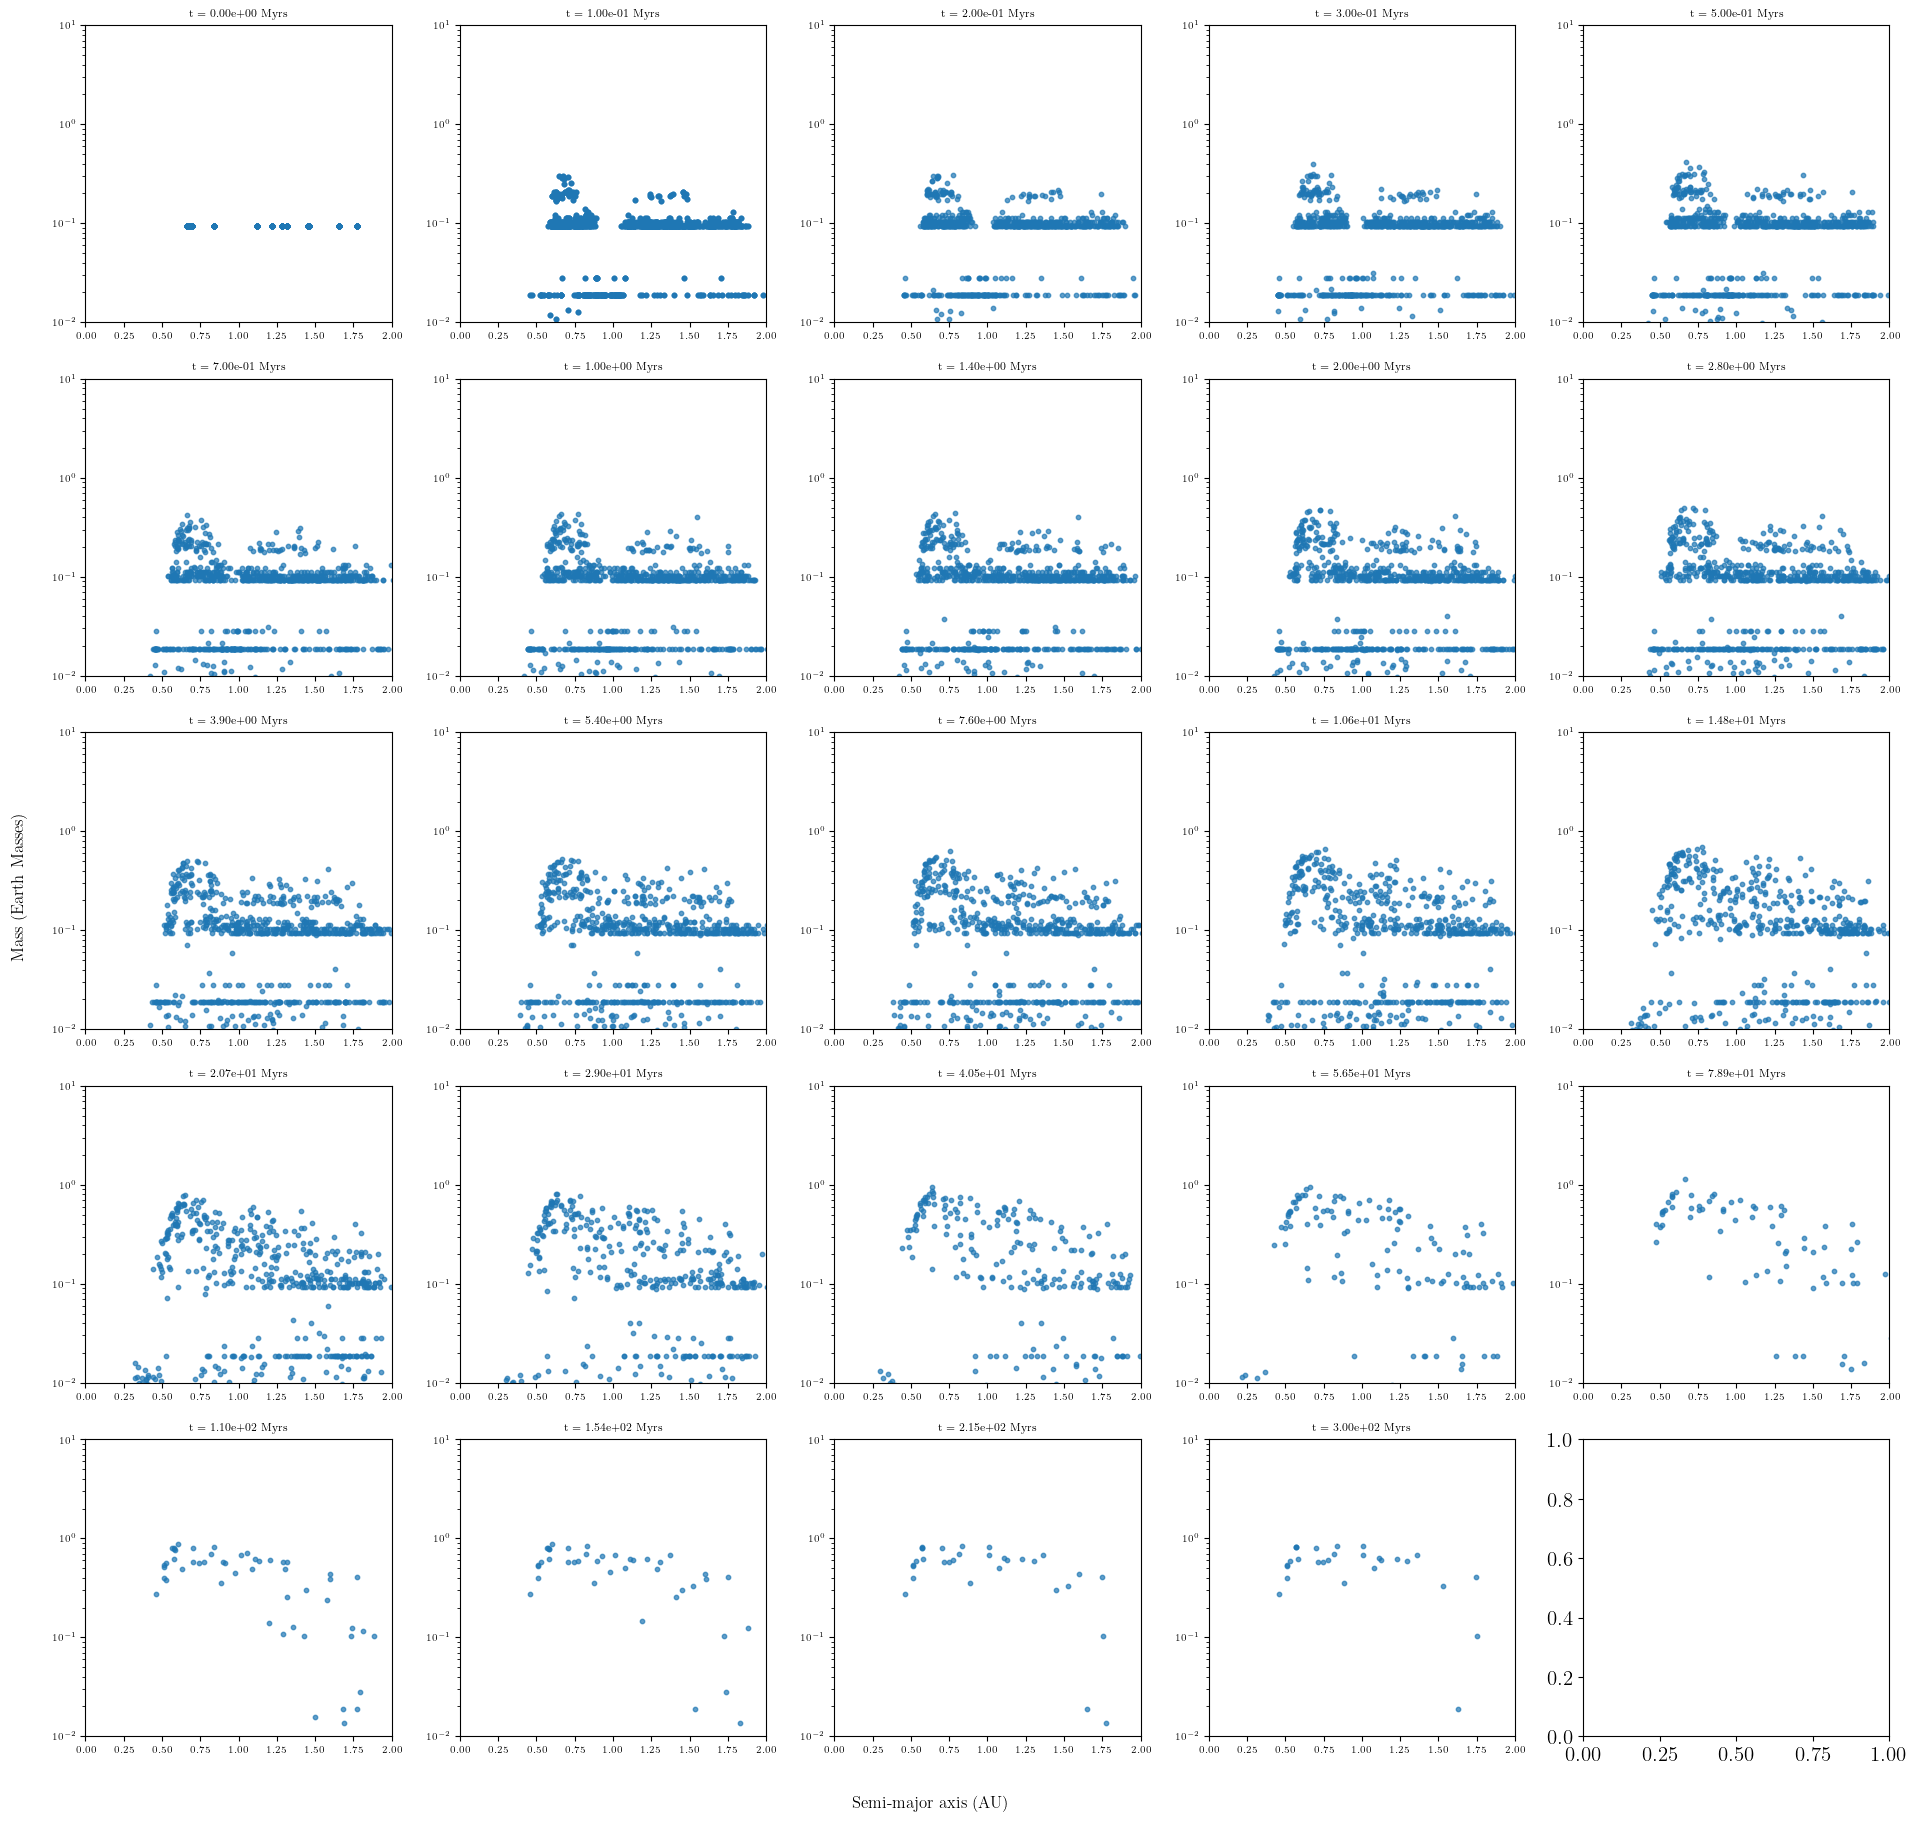

In [23]:
import matplotlib.pyplot as plt

indices = df['index'].unique()

fig, axes = plt.subplots(5, 5, figsize=(20, 20))
axes = axes.flatten()

for k in range(25):   # 5x5 grid
    if k >= len(indices):
        break
    ax = axes[k]
    df_plot = df[df['index'] == indices[k]]
    ax.scatter(df_plot['a'], df_plot['m'] * sol_to_earth, s=10, alpha=0.7)
    ax.set_xlim(0, 2)
    ax.set_ylim(1e-2, 10)  # log scale works better if >0
    ax.set_yscale('log')
    time_plot = df_plot['time'].unique()/1e6
    time_plot = time_plot[0]
    ax.set_title(f"t = {time_plot:.2e} Myrs", fontsize=8)
    ax.tick_params(axis='both', which='major', labelsize=7)

# Add global labels
fig.text(0.5, 0.04, 'Semi-major axis (AU)', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'Mass (Earth Masses)', va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
plt.show()


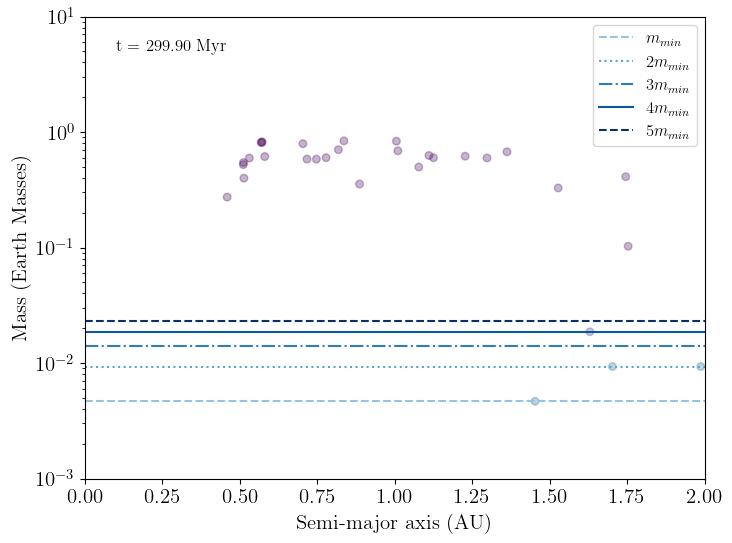

In [24]:
from matplotlib.animation import FuncAnimation

indices = np.sort(df['index'].unique())   # all snapshot indices

fig, ax = plt.subplots(figsize=(8,6))

scat = ax.scatter([], [], s=30, alpha=0.3, color = 'black')
n_lines = 5
m_min = 0.5 * 2.8e-8 * sol_to_earth
colors = plt.cm.Blues(np.linspace(0.4, 1.0, n_lines))
linestyles = ['--', ':', '-.', '-', '--']
labels = [r'$m_{min}$', r'$2 m_{min}$', r'$3 m_{min}$', r'$4 m_{min}$', r'$5 m_{min}$']
for i in range(n_lines):
    ax.axhline((i+1) * m_min, linestyle=linestyles[i], color=colors[i], label=labels[i])


unique_hashes = df['particle_hash'].unique()
n_particles = len(unique_hashes)

cmap = plt.cm.viridis  # you can choose 'plasma', 'cividis', etc.
hash_to_color = {h: cmap(i / n_particles) for i, h in enumerate(unique_hashes)}



time_text = ax.text(0.05, 0.95, '', transform=ax.transAxes, fontsize=12, va='top')

ax.legend(fontsize=12)
ax.set_xlim(0, 2)
ax.set_ylim(1e-3, 10)
ax.set_yscale('log')
ax.set_xlabel("Semi-major axis (AU)")
ax.set_ylabel("Mass (Earth Masses)")

def update(frame_idx):
    snap_index = indices[frame_idx]
    df_plot = df[df['index'] == snap_index]

    clr = df_plot['particle_hash'].map(hash_to_color)
    scat.set_offsets(np.c_[df_plot['a'], df_plot['m'] * sol_to_earth])
    scat.set_color(clr)
    time_text.set_text(f"t = {df_plot['time'].iloc[0]/1e6:.2f} Myr")

    return scat, time_text

anim = FuncAnimation(fig, update, frames=len(indices), interval=500, blit=False, repeat=True)
anim.save("cham_bi_tajer_m_a_anim.gif", writer="pillow", dpi=100, fps=2)
plt.show()


In [25]:
turning_points = df[(df['time'] < 10.6e6 + 0.1e6) & (df['time'] > 10.6e6 + -0.1e6)]
inner_ones = turning_points[turning_points['a'] < 0.7]

In [26]:
df['time'].unique()

array([0.00000000e+00, 1.00000011e+05, 2.00000005e+05, 3.00000000e+05,
       5.00000006e+05, 7.00000011e+05, 1.00000001e+06, 1.40000000e+06,
       2.00000000e+06, 2.80000001e+06, 3.90000001e+06, 5.40000001e+06,
       7.60000001e+06, 1.06000000e+07, 1.48000000e+07, 2.07000000e+07,
       2.90000000e+07, 4.05000000e+07, 5.65000000e+07, 7.89000000e+07,
       1.10200000e+08, 1.53800000e+08, 2.14800000e+08, 2.99900000e+08])

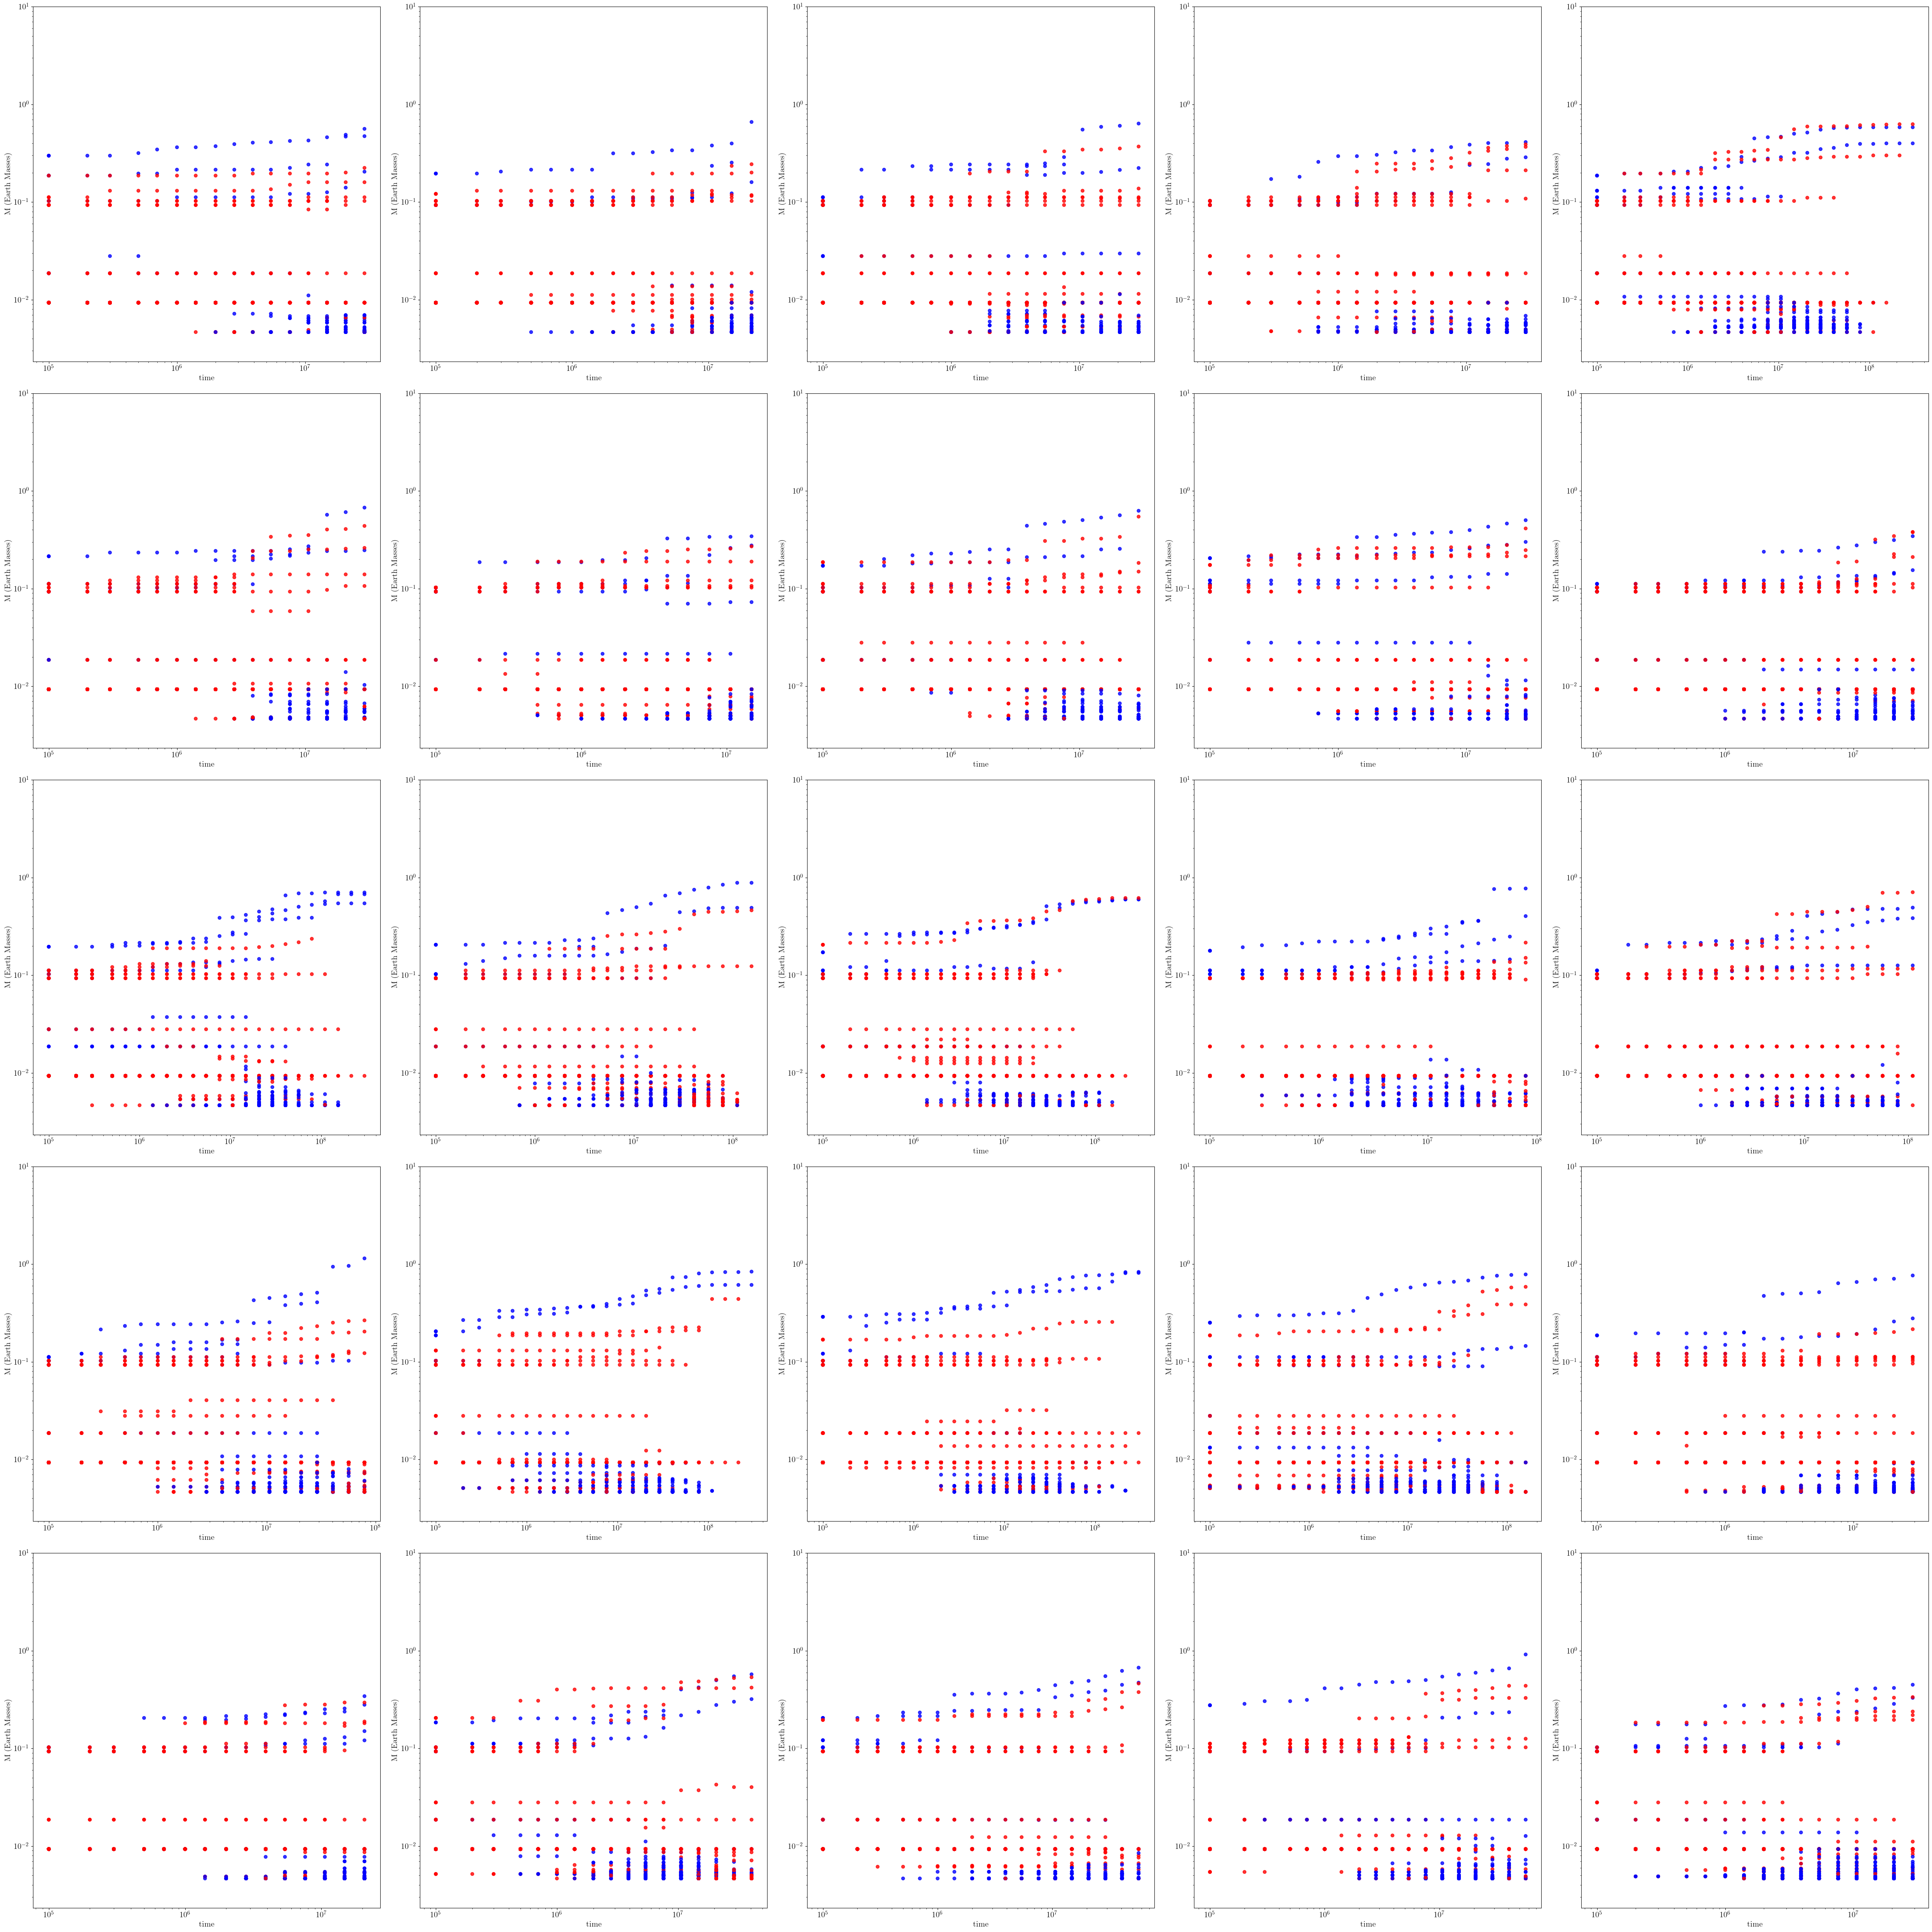

In [27]:
# get unique particle hashes
turning_points = df[(df['time'] < 20.7e6 + 0.1e6) & (df['time'] > 20.7e6 + -0.1e6)]
inner_ones = turning_points[turning_points['a'] < 0.5]

unique_hashes = df['particle_hash'].unique()
n_particles = len(unique_hashes)

# assign colors based on whether particle_hash is in inner_ones
df['color'] = np.where(df['particle_hash'].isin(inner_ones['particle_hash']), 'blue', 'red')


plt.figure(figsize=(50,50))
for i in range(25):
    plt.subplot(5,5,i+1)
    plot_df = df[df['sim_id'] == i+1]
    plt.scatter(plot_df['time'], plot_df['m'] * sol_to_earth, color = plot_df['color'], alpha = 0.8)
    plt.yscale('log')
    plt.xscale('log')
    plt.ylim(0.5 * m_min, 10)
    plt.xlabel('time')
    plt.ylabel('M (Earth Masses)')


plt.tight_layout()
plt.show()

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/2078217169.py:10: Us

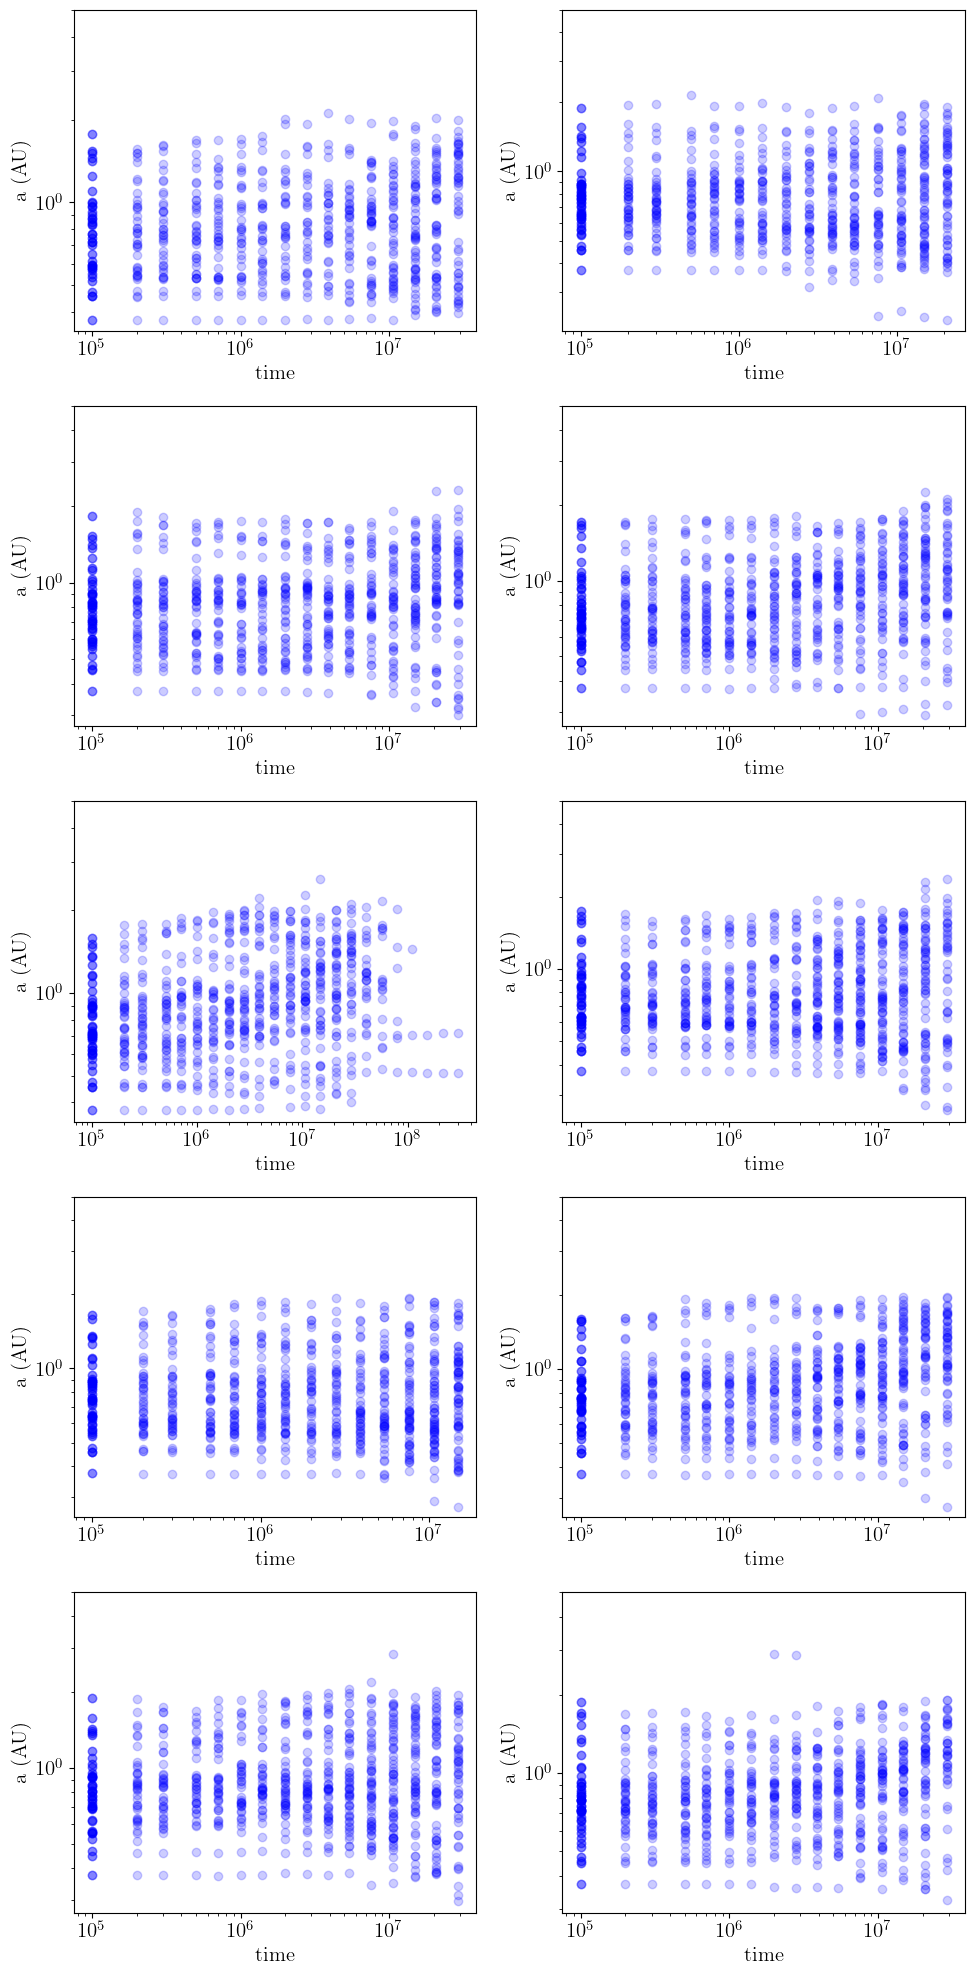

In [28]:
plt.figure(figsize=(10,20))
for i in range(10):
    plt.subplot(5,2,i+1)
    plot_df = df[df['sim_id'] == i+1]
    plot_df_blue = plot_df[plot_df['color'] == 'blue']
    plt.scatter(plot_df_blue['time'], plot_df_blue['a'], color = 'blue', alpha = 0.2)
    #plt.scatter(plot_df['time'], plot_df['a'], color = plot_df['color'], alpha = 0.2)
    plt.yscale('log')
    plt.xscale('log')
    plt.ylim(0,5)
    plt.xlabel('time')
    plt.ylabel('a (AU)')


plt.tight_layout()
plt.show()

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/1262703780.py:10: Us

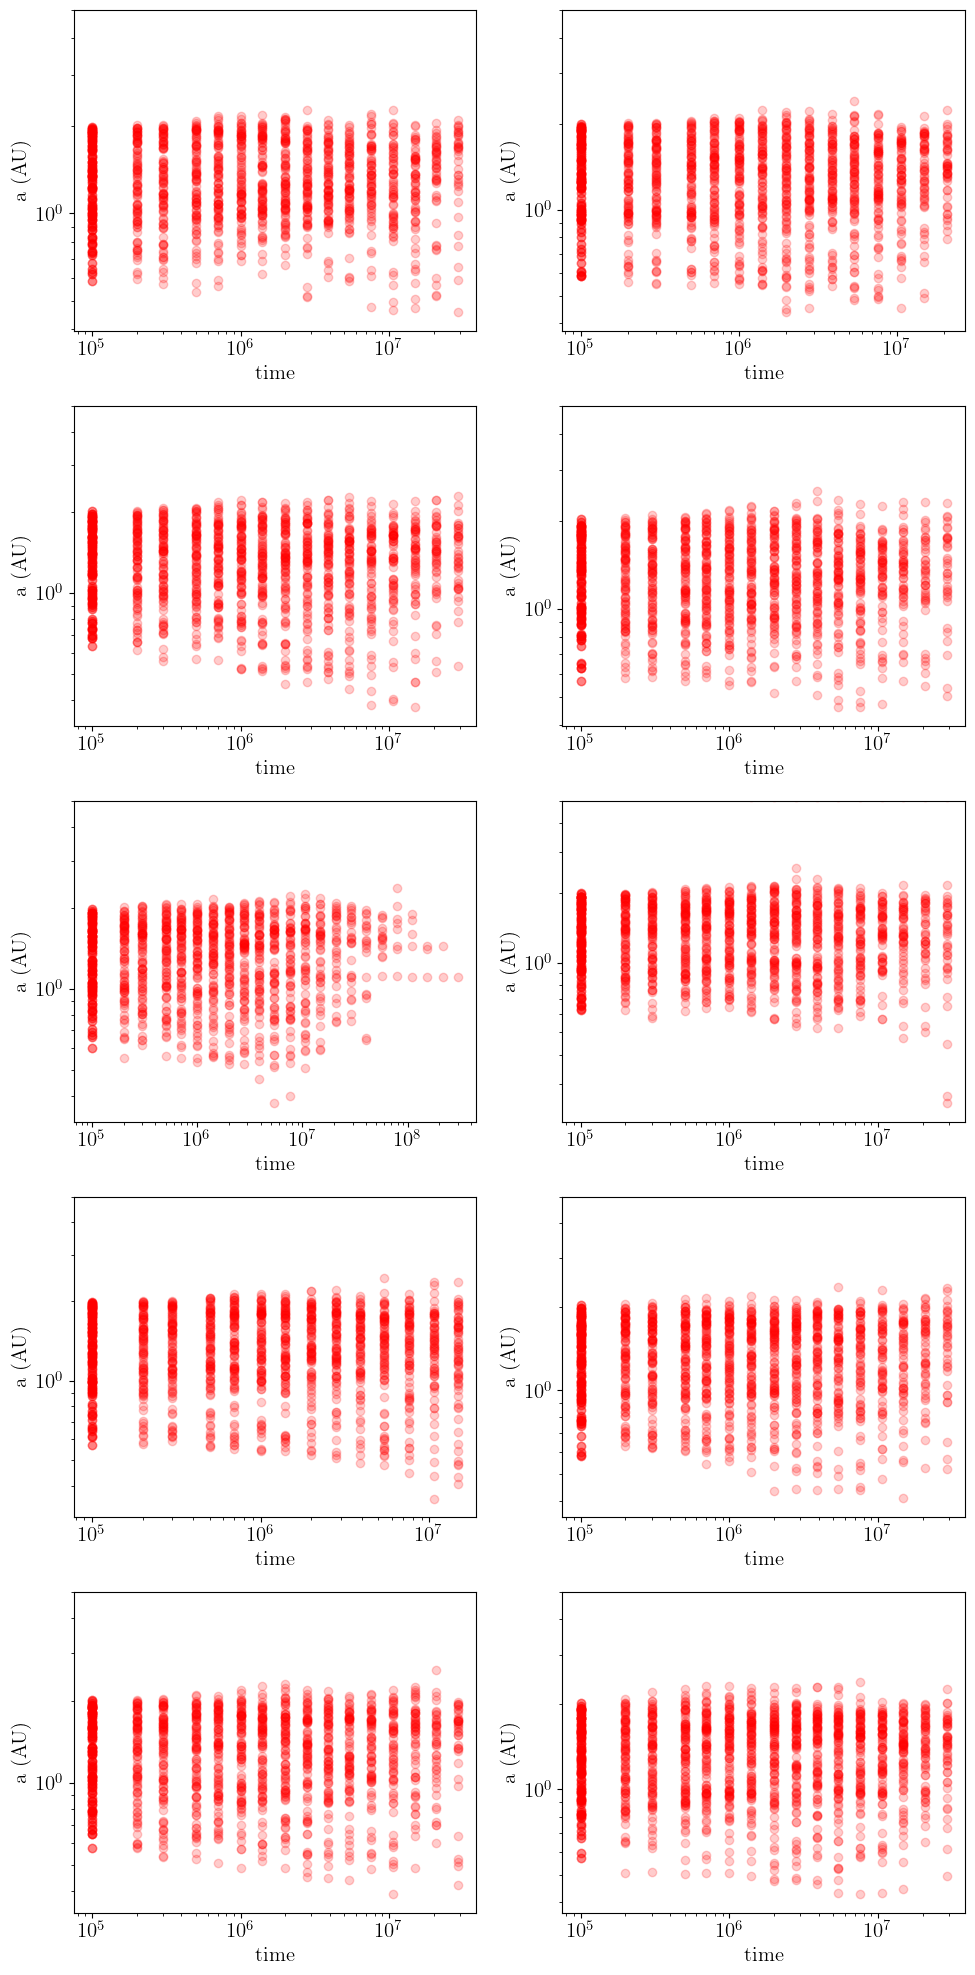

In [29]:
plt.figure(figsize=(10,20))
for i in range(10):
    plt.subplot(5,2,i+1)
    plot_df = df[df['sim_id'] == i+1]
    plot_df_blue = plot_df[plot_df['color'] == 'red']
    plt.scatter(plot_df_blue['time'], plot_df_blue['a'], color = 'red', alpha = 0.2)
    #plt.scatter(plot_df['time'], plot_df['a'], color = plot_df['color'], alpha = 0.2)
    plt.yscale('log')
    plt.xscale('log')
    plt.ylim(0,5)
    plt.xlabel('time')
    plt.ylabel('a (AU)')


plt.tight_layout()
plt.show()

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0,5)
/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_61794/4244535117.py:10: Us

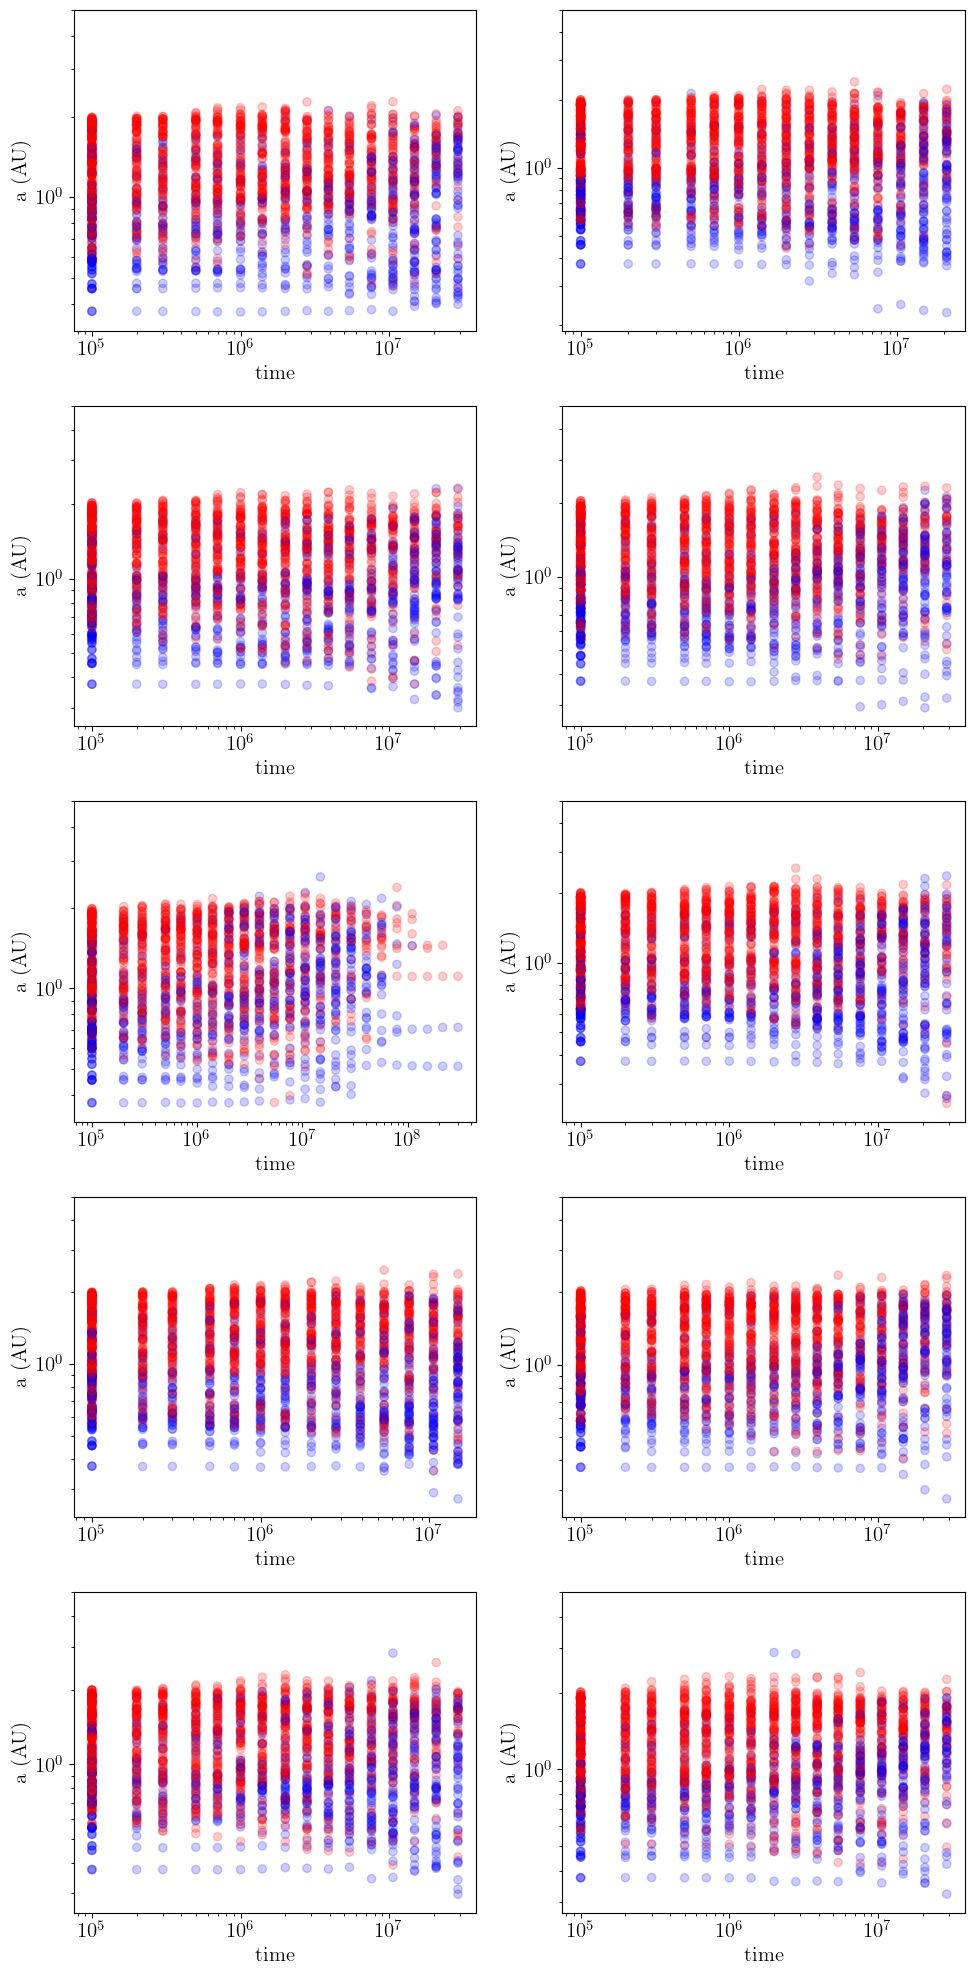

In [30]:
plt.figure(figsize=(10,20))
for i in range(10):
    plt.subplot(5,2,i+1)
    plot_df = df[df['sim_id'] == i+1]
    #plot_df_blue = plot_df[plot_df['color'] == 'blue']
    #plt.scatter(plot_df_blue['time'], plot_df_blue['a'], color = 'blue', alpha = 0.2)
    plt.scatter(plot_df['time'], plot_df['a'], color = plot_df['color'], alpha = 0.2)
    plt.yscale('log')
    plt.xscale('log')
    plt.ylim(0,5)
    plt.xlabel('time')
    plt.ylabel('a (AU)')


plt.tight_layout()
plt.show()

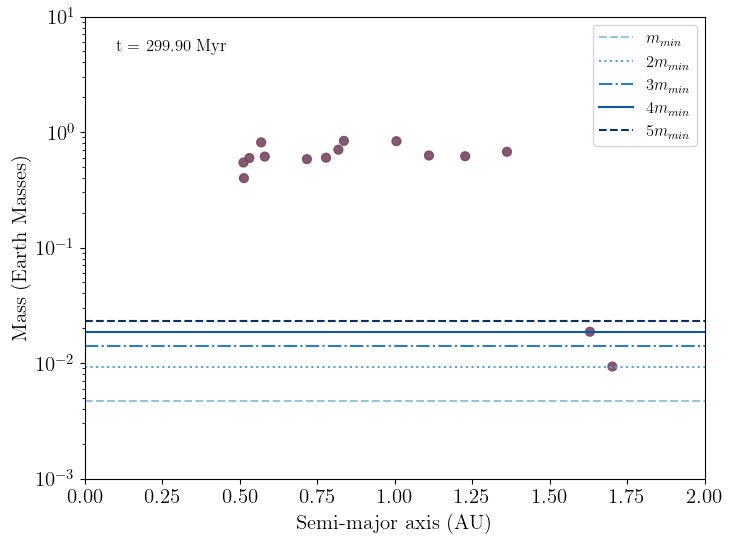

In [31]:
from matplotlib.animation import FuncAnimation
from pypalettes import load_cmap

indices = np.sort(df['index'].unique())   # all snapshot indices

fig, ax = plt.subplots(figsize=(8,6))

scat = ax.scatter([], [], s=40, alpha=0.9, color = 'black')
n_lines = 5
colors = plt.cm.Blues(np.linspace(0.4, 1.0, n_lines))
linestyles = ['--', ':', '-.', '-', '--']
labels = [r'$m_{min}$', r'$2 m_{min}$', r'$3 m_{min}$', r'$4 m_{min}$', r'$5 m_{min}$']
for i in range(n_lines):
    ax.axhline((i+1) * m_min, linestyle=linestyles[i], color=colors[i], label=labels[i])


unique_hashes = df['particle_hash'].unique()
n_particles = len(unique_hashes)

cmap = load_cmap('Autumn')
norm = plt.Normalize(vmin=unique_hashes.min(), vmax=unique_hashes.max())

time_text = ax.text(0.05, 0.95, '', transform=ax.transAxes, fontsize=12, va='top')

ax.legend(fontsize=12)
ax.set_xlim(0, 2)
ax.set_ylim(1e-3, 10)
ax.set_yscale('log')
ax.set_xlabel("Semi-major axis (AU)")
ax.set_ylabel("Mass (Earth Masses)")

def update(frame_idx):
    snap_index = indices[frame_idx]
    df_plot = df[df['index'] == snap_index]
    df_plot = df_plot[df_plot['sim_id'] < 20]

    clr = cmap(norm(df_plot['particle_hash']))
    scat.set_offsets(np.c_[df_plot['a'], df_plot['m'] * sol_to_earth])
    scat.set_color(clr)
    time_text.set_text(f"t = {df_plot['time'].iloc[0]/1e6:.2f} Myr")

    return scat, time_text

anim = FuncAnimation(fig, update, frames=len(indices), interval=500, blit=False, repeat=True)
anim.save("cham_bi_tajer_m_a_anim_1.gif", writer="pillow", dpi=100, fps=2)
plt.show()
